# Deep Learning, Phase 3 (Sequential Models), Day 1: Sequential Data, the RNN Cell and Time-Series Data Preparation
Today (NumPy only, no GPU):
1. What is sequential data?  2. The RNN cell by hand  3. Hidden state as memory (and forgetting)  4. A time series and sliding windows  5. **Why we split by time, not randomly**  6. Scaling without leakage  7. Baselines to beat

*Read first (20 min):* Karpathy, "The Unreasonable Effectiveness of Recurrent Neural Networks" (first part) https://karpathy.github.io/2015/05/21/rnn-effectiveness/

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. Sequential data
In a **sequence** the **order** carries information, and the length can vary. Examples: daily temperature, stock prices, sensor readings, a sentence (words in order), a heartbeat signal. Shuffle the order of a sentence and it loses its meaning.

An MLP or a CNN on a fixed window has no **memory** of what came before the window, and cannot handle a different length. A **recurrent neural network (RNN)** processes one element at a time and carries a **hidden state** along: a vector that summarises everything it has seen so far.

Sequence tasks come in several shapes:
| Pattern | Example |
|---|---|
| **Many-to-one** | a whole sequence in, one answer out (classify an ECG, predict the next price) |
| **Many-to-many** | a sequence in, a sequence out (translate a sentence, label every word) |
| **One-to-many** | one input, a sequence out (generate a caption for an image) |

Today and the next days we mostly use many-to-one.

## 2. The RNN cell by hand
At every time step `t` the RNN reads the input `x_t` and the previous hidden state `h_(t-1)` and computes a new hidden state:

**h_t = tanh( W_x x_t + W_h h_(t-1) + b )**

- `W_x` weights the **current input**, `W_h` weights the **previous hidden state** (the memory), `b` is the bias.
- The **same weights** are used at every time step (like a CNN filter reused across the image, but across time).
- The hidden state starts as zeros: `h_0 = 0`.

Shapes for input size 1 and hidden size 4: `x_t` (1), `W_x` (4, 1), `h` (4), `W_h` (4, 4), `b` (4).

Input sequence : [ 0.5 -1.   0.8  0.   1.5 -0.3]
Hidden states (one row per time step, one column per hidden unit):
[[ 0.608  0.159  0.373  0.715]
 [-0.663  0.224 -0.328 -0.922]
 [ 0.305 -0.343  0.16   0.851]
 [ 0.433  0.496  0.266 -0.075]
 [ 0.984  0.481  0.889  0.995]
 [ 0.542  0.629  0.487 -0.137]]


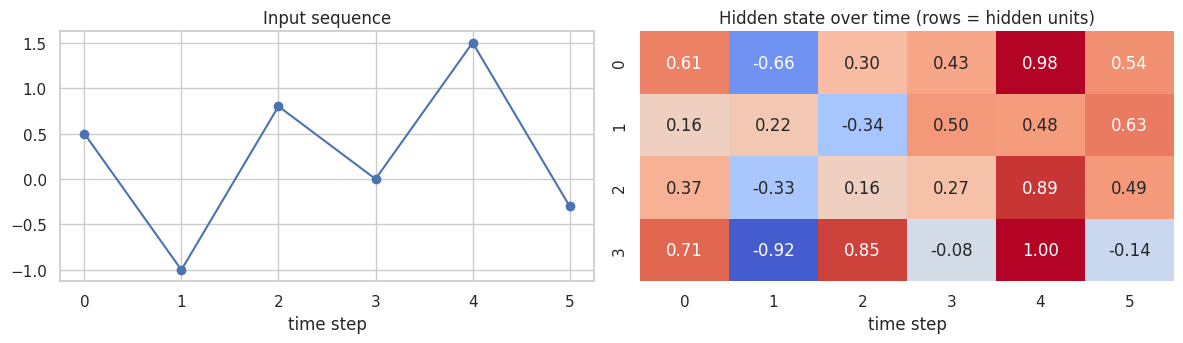

In [2]:
n_in, n_hid = 1, 4
rng = np.random.RandomState(0)
W_x = rng.randn(n_hid, n_in) * 0.8        # input -> hidden
W_h = rng.randn(n_hid, n_hid) * 0.5       # hidden -> hidden (the memory connection)
b = np.zeros(n_hid)

def rnn_forward(seq, return_all=True):
    h = np.zeros(n_hid); states = []
    for x_t in seq:                                          # one step at a time, always the same weights
        h = np.tanh(W_x @ np.atleast_1d(x_t) + W_h @ h + b)
        states.append(h.copy())
    return np.array(states) if return_all else h

seq = np.array([0.5, -1.0, 0.8, 0.0, 1.5, -0.3])
H = rnn_forward(seq)
print('Input sequence :', seq)
print('Hidden states (one row per time step, one column per hidden unit):'); print(H.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(seq, 'o-'); ax[0].set(title='Input sequence', xlabel='time step')
sns.heatmap(H.T, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=False, ax=ax[1]); ax[1].set(title='Hidden state over time (rows = hidden units)', xlabel='time step')
plt.tight_layout(); plt.show()

**Unrolling:** an RNN is the same cell copied once per time step, passing `h` from one copy to the next:

`h_0 -> [cell with x_1] -> h_1 -> [cell with x_2] -> h_2 -> ... -> h_T`

For a **many-to-one** task we take the **last** hidden state `h_T` and feed it to a normal linear layer to get the answer (a number for forecasting, class scores for classification). Here with random, untrained weights:

In [3]:
W_out = rng.randn(1, n_hid); b_out = np.zeros(1)
h_last = rnn_forward(seq, return_all=False)
print('Last hidden state:', h_last.round(3)); print('Untrained prediction:', (W_out @ h_last + b_out).round(3), '(random numbers: training will fix the weights)')
n_params = W_x.size + W_h.size + b.size + W_out.size + b_out.size
print('Parameters:', n_params, '= W_x', W_x.size, '+ W_h', W_h.size, '+ b', b.size, '+ output layer', W_out.size + b_out.size)
print('Note: the number of parameters does NOT depend on the sequence length.')

Last hidden state: [ 0.542  0.629  0.487 -0.137]
Untrained prediction: [-0.451] (random numbers: training will fix the weights)
Parameters: 29 = W_x 4 + W_h 16 + b 4 + output layer 5
Note: the number of parameters does NOT depend on the sequence length.


## 3. The hidden state is a memory (but a leaky one)
Two sequences that differ **only in the very first value**. How long does the difference survive in the hidden state? We measure the distance between the two hidden states at every step:

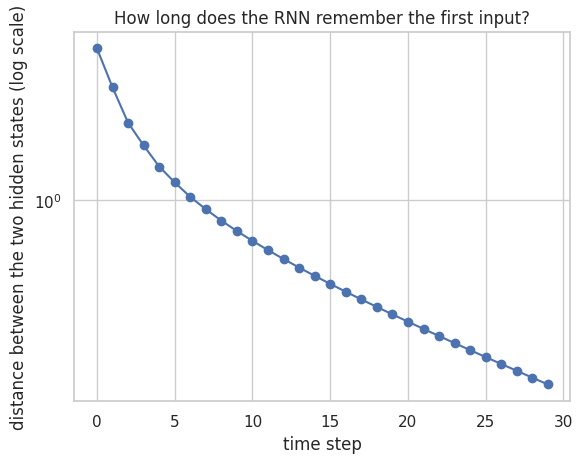

Difference after 1 step : 3.5451
Difference after 10 steps: 0.774617
Difference after 30 steps: 2.16e-01


In [4]:
a = np.concatenate([[2.0], np.zeros(29)])        # a big first value, then silence
b2 = np.concatenate([[-2.0], np.zeros(29)])
Ha, Hb = rnn_forward(a), rnn_forward(b2)
diff = np.linalg.norm(Ha - Hb, axis=1)
plt.semilogy(diff, 'o-'); plt.xlabel('time step'); plt.ylabel('distance between the two hidden states (log scale)')
plt.title('How long does the RNN remember the first input?'); plt.show()
print('Difference after 1 step : %.4f' % diff[0]); print('Difference after 10 steps: %.6f' % diff[9]); print('Difference after 30 steps: %.2e' % diff[-1])



## 4. A time series and sliding windows
We create a noisy series: two sine waves of different speeds plus noise.

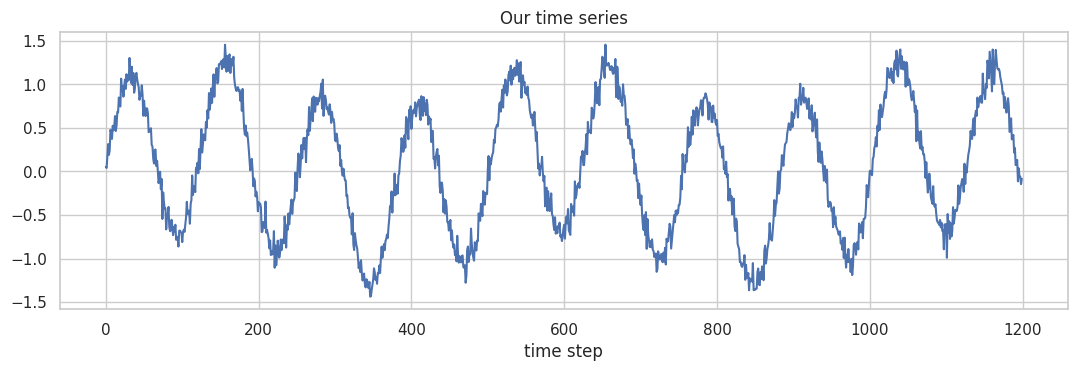

In [5]:
n = 1200; t = np.arange(n)
series = np.sin(0.05 * t) + 0.3 * np.sin(0.013 * t) + 0.1 * np.random.randn(n)
plt.figure(figsize=(13, 3.6)); plt.plot(series); plt.title('Our time series'); plt.xlabel('time step'); plt.show()

To **forecast** with a model we turn the series into supervised examples with a **sliding window**: the last `k` values are the input `X`, the next value is the target `y`.

`[v0 v1 v2 v3 v4] -> v5`, then `[v1 v2 v3 v4 v5] -> v6`, and so on.

In [6]:
def make_windows(x, k):
    X = np.array([x[i:i + k] for i in range(len(x) - k)])      # shape (n_windows, k)
    y = x[k:]                                                  # the value right after each window
    return X, y

X_demo, y_demo = make_windows(np.arange(10.0), k=4)
print('Toy series 0..9 with window k=4:')
for xi, yi in zip(X_demo, y_demo): print(' ', xi, '->', yi)
print('X shape', X_demo.shape, '| y shape', y_demo.shape)
print('\nFor an RNN in PyTorch the input needs a features axis: (batch, time, features) =', X_demo[..., None].shape)

Toy series 0..9 with window k=4:
  [0. 1. 2. 3.] -> 4.0
  [1. 2. 3. 4.] -> 5.0
  [2. 3. 4. 5.] -> 6.0
  [3. 4. 5. 6.] -> 7.0
  [4. 5. 6. 7.] -> 8.0
  [5. 6. 7. 8.] -> 9.0
X shape (6, 4) | y shape (6,)

For an RNN in PyTorch the input needs a features axis: (batch, time, features) = (6, 4, 1)


## 5. Split by time, never randomly
For a time series, the model will be used on the **future**, so the test set must be the **last** part of the series. A random split is wrong for two reasons:
1. Neighbouring windows **overlap** almost completely, so test windows are nearly copies of training windows (leakage).
2. The test points sit *between* training points (interpolation), which is much easier than predicting the future (extrapolation).

See it: a trending series, a Random Forest on windows of 10 values. Same model, same data, two ways of splitting:

In [7]:
trend = 0.02 * t + np.sin(0.05 * t) + 0.1 * np.random.randn(n)        # a series that keeps rising
Xw, yw = make_windows(trend, 10)

idx = np.random.RandomState(0).permutation(len(Xw)); cut = int(0.8 * len(Xw))
rf = RandomForestRegressor(n_estimators=100, random_state=0).fit(Xw[idx[:cut]], yw[idx[:cut]])
mae_random = mean_absolute_error(yw[idx[cut:]], rf.predict(Xw[idx[cut:]]))             # WRONG: random split

rf = RandomForestRegressor(n_estimators=100, random_state=0).fit(Xw[:cut], yw[:cut])
mae_time = mean_absolute_error(yw[cut:], rf.predict(Xw[cut:]))                          # RIGHT: the future is the test set
print(f'MAE with a random split : {mae_random:.3f}   <- looks great, but is misleading')
print(f'MAE with a time split   : {mae_time:.3f}   <- the honest estimate for forecasting')

MAE with a random split : 0.112   <- looks great, but is misleading
MAE with a time split   : 2.507   <- the honest estimate for forecasting


A random split makes the model look much better than it really is. (The Random Forest cannot predict values higher than anything it has seen, and in the time split the future values are all higher.) **Always split by time.**

For our sine series we split into **train 70%, validation 15%, test 15%** in time order. The test part stays locked until the final evaluation (Day 6 for the project).

Another detail: we split the **raw series first**, and **then** create the windows inside each part, so that no window crosses the boundary.

Train: 840 | Validation: 180 | Test (locked): 180


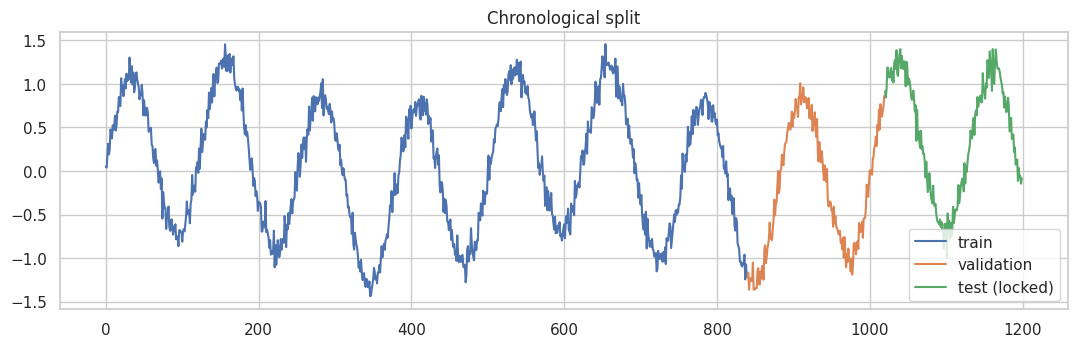

In [8]:
n_tr, n_va = int(0.70 * n), int(0.15 * n)
s_train, s_val, s_test = series[:n_tr], series[n_tr:n_tr + n_va], series[n_tr + n_va:]
print('Train:', len(s_train), '| Validation:', len(s_val), '| Test (locked):', len(s_test))
plt.figure(figsize=(13, 3.6))
plt.plot(range(n_tr), s_train, label='train'); plt.plot(range(n_tr, n_tr + n_va), s_val, label='validation'); plt.plot(range(n_tr + n_va, n), s_test, label='test (locked)')
plt.legend(); plt.title('Chronological split'); plt.show()

## 6. Scaling without leakage
As in Weeks 2 to 4: the scaler learns its mean and standard deviation from the **training part only**, then transforms all parts. (If the scaler saw the test data, information from the future would leak into training.)

In [9]:
scaler = StandardScaler().fit(s_train.reshape(-1, 1))
tr, va, te = (scaler.transform(s.reshape(-1, 1)).ravel() for s in (s_train, s_val, s_test))
print(f'Scaler learned from train only: mean {scaler.mean_[0]:.3f}, std {np.sqrt(scaler.var_[0]):.3f}')

K = 20                                                          # window length: how many past values the model sees
Xtr, ytr = make_windows(tr, K); Xva, yva = make_windows(va, K); Xte, yte = make_windows(te, K)
print('Windows  train', Xtr.shape, '| validation', Xva.shape, '| test', Xte.shape)

Scaler learned from train only: mean 0.063, std 0.731
Windows  train (820, 20) | validation (160, 20) | test (160, 20)


## 7. Baselines to beat
Before any neural network, we need simple models. If the LSTM cannot beat them, it is not worth using.
1. **Naive:** the next value equals the last value (`tomorrow = today`).
2. **Moving average:** the mean of the last `k` values.
3. **Linear regression** on the window.

Scores on the **validation** set (in scaled units; MAE = average absolute error, RMSE penalises big errors more).

,MAE,RMSE
Naive (last value),0.1548,0.1894
Moving average,0.4871,0.5398
Linear regression,0.1156,0.1440


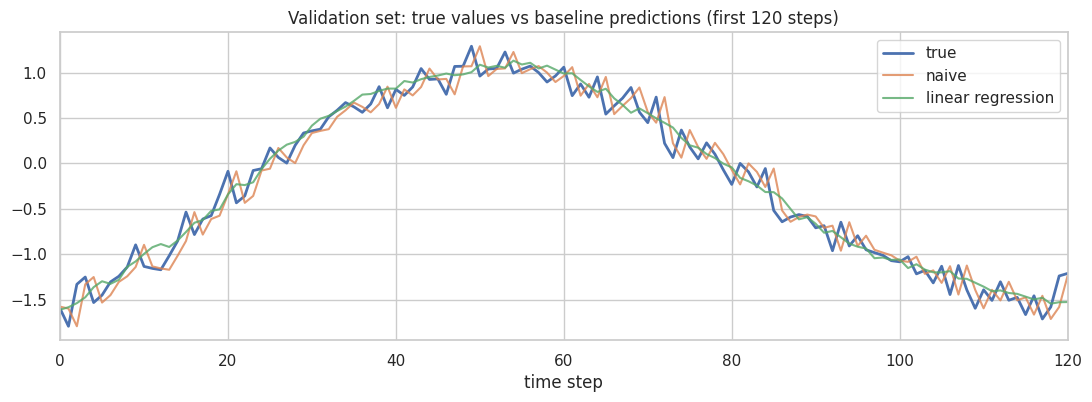

In [10]:
def scores(y_true, y_pred): return {'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}

pred_naive = Xva[:, -1]
pred_ma = Xva.mean(axis=1)
lin = LinearRegression().fit(Xtr, ytr); pred_lin = lin.predict(Xva)
res = pd.DataFrame({'Naive (last value)': scores(yva, pred_naive), 'Moving average': scores(yva, pred_ma), 'Linear regression': scores(yva, pred_lin)}).T.round(4)
display(res)

plt.figure(figsize=(13, 4)); plt.plot(yva, label='true', lw=2)
plt.plot(pred_naive, label='naive', alpha=.8); plt.plot(pred_lin, label='linear regression', alpha=.8)
plt.xlim(0, 120); plt.legend(); plt.title('Validation set: true values vs baseline predictions (first 120 steps)'); plt.xlabel('time step'); plt.show()